In [ ]:
"""
Employee Turnover Prediction

This project uses historical HR data to predict whether an employee is likely to leave the company. 
Understanding why employees leave helps organizations improve retention strategies, reduce hiring costs, and maintain productivity.

Objective
- Build predictive models to classify employees as likely to stay or leave.
- Identify key factors influencing turnover.
- Deliver actionable insights to Human Resources teams.

Dataset Overview
The dataset includes various employee attributes such as:
- Department
- Salary level
- Satisfaction score
- Promotion and bonus history
- Average monthly hours
- Tenure (years at company)
- Performance review scores

The target variable is **`left`** (1 = left, 0 = stayed).

"""

In [1]:
# Importing Libraries Needed for Analysis

# Data manipulation and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Modeling and evaluation
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)

# Set Seaborn style
sns.set(style='whitegrid')


In [2]:
# Load the dataset
df = pd.read_csv("/Users/christongreene/Desktop/Data/employee_churn_data.csv")

# Preview the first few rows
df.head()


,department,promoted,review,projects,salary,tenure,satisfaction,bonus,avg_hrs_month,left
0,operations,0,0.577569,3,low,5.0,0.626759,0,180.866070,no
1,operations,0,0.751900,3,medium,6.0,0.443679,0,182.708149,no
2,support,0,0.722548,3,medium,6.0,0.446823,0,184.416084,no
3,logistics,0,0.675158,4,high,8.0,0.440139,0,188.707545,no
4,sales,0,0.676203,3,high,5.0,0.577607,1,179.821083,no


In [3]:
# basic info on dataset structure

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9540 entries, 0 to 9539
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   department     9540 non-null   object 
 1   promoted       9540 non-null   int64  
 2   review         9540 non-null   float64
 3   projects       9540 non-null   int64  
 4   salary         9540 non-null   object 
 5   tenure         9540 non-null   float64
 6   satisfaction   9540 non-null   float64
 7   bonus          9540 non-null   int64  
 8   avg_hrs_month  9540 non-null   float64
 9   left           9540 non-null   object 
dtypes: float64(4), int64(3), object(3)
memory usage: 745.4+ KB


In [5]:
# Summary statistics for numercial columns

df.describe()

,promoted,review,projects,tenure,satisfaction,bonus,avg_hrs_month
count,9540.000000,9540.000000,9540.000000,9540.000000,9540.000000,9540.000000,9540.000000
mean,0.030294,0.651826,3.274843,6.556184,0.504645,0.212055,184.661571
std,0.171403,0.085307,0.579136,1.415432,0.158555,0.408785,4.144831
min,0.000000,0.310000,2.000000,2.000000,0.000000,0.000000,171.374060
25%,0.000000,0.592884,3.000000,5.000000,0.386801,0.000000,181.472085
50%,0.000000,0.647456,3.000000,7.000000,0.500786,0.000000,184.628796
75%,0.000000,0.708379,4.000000,8.000000,0.622607,0.000000,187.728708
max,1.000000,1.000000,5.000000,12.000000,1.000000,1.000000,200.861656


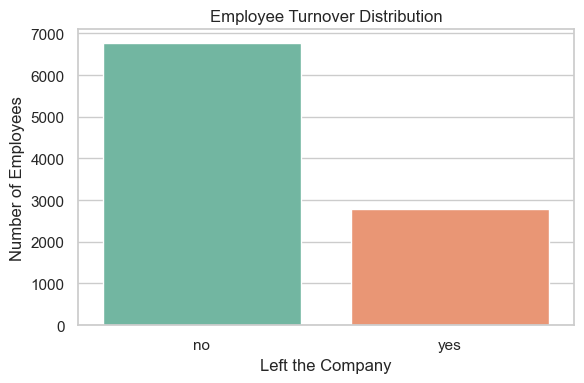

In [7]:
# Visualize the overall distribution of employee turnover (who stayed vs who left)
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='left', hue='left', palette='Set2', legend=False)
plt.title('Employee Turnover Distribution')
plt.xlabel('Left the Company')
plt.ylabel('Number of Employees')
plt.tight_layout()
plt.show()


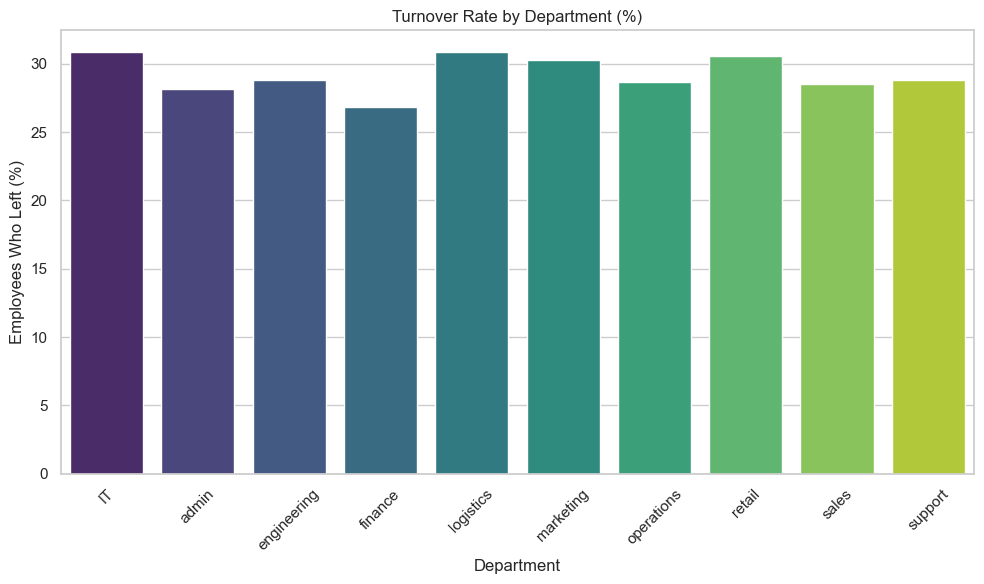

In [9]:
# Calculate turnover percentage by department
dept_turnover = df.groupby('department')['left'].value_counts(normalize=True).unstack().fillna(0) * 100
dept_turnover['left_yes'] = dept_turnover.get('yes', 0)

# Bar plot of turnover rate by department
plt.figure(figsize=(10, 6))
sns.barplot(x=dept_turnover.index, y=dept_turnover['left_yes'], hue=dept_turnover.index, palette='viridis', legend= False)
plt.title('Turnover Rate by Department (%)')
plt.ylabel('Employees Who Left (%)')
plt.xlabel('Department')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


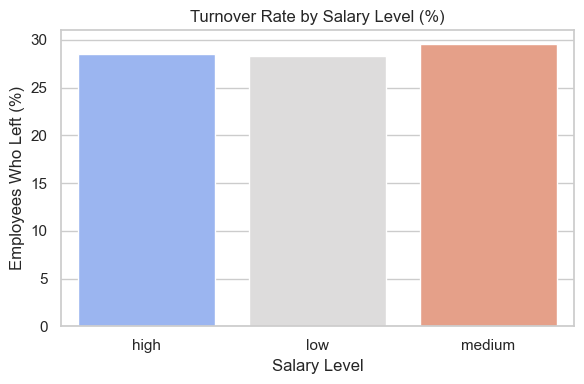

In [13]:
# Calculate percentage of employees who left per salary level
salary_turnover = df.groupby('salary')['left'].value_counts(normalize=True).unstack().fillna(0) * 100
salary_turnover['left_yes'] = salary_turnover.get('yes', 0)

# Plot turnover rate by salary level
plt.figure(figsize=(6, 4))
sns.barplot(x=salary_turnover.index, y=salary_turnover['left_yes'], hue=salary_turnover.index, palette='coolwarm', legend=False)
plt.title('Turnover Rate by Salary Level (%)')
plt.ylabel('Employees Who Left (%)')
plt.xlabel('Salary Level')
plt.tight_layout()
plt.show()


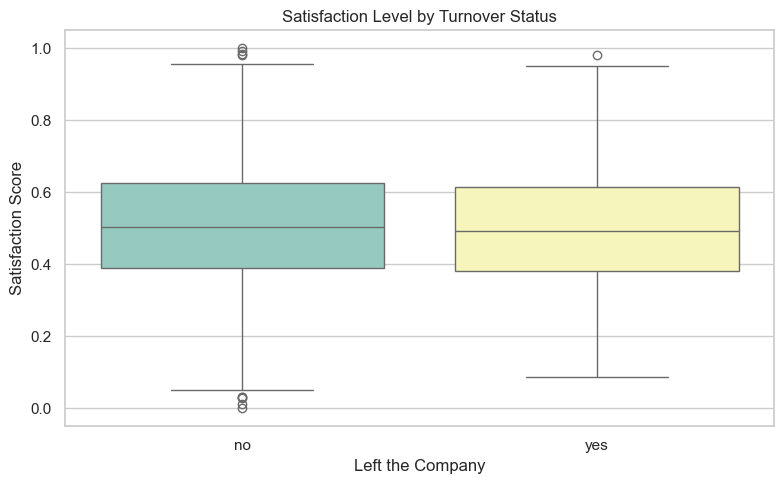

In [14]:
# Compare satisfaction scores between employees who left and those who stayed
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='left', y='satisfaction', hue='left', palette='Set3', legend=False)
plt.title('Satisfaction Level by Turnover Status')
plt.xlabel('Left the Company')
plt.ylabel('Satisfaction Score')
plt.tight_layout()
plt.show()


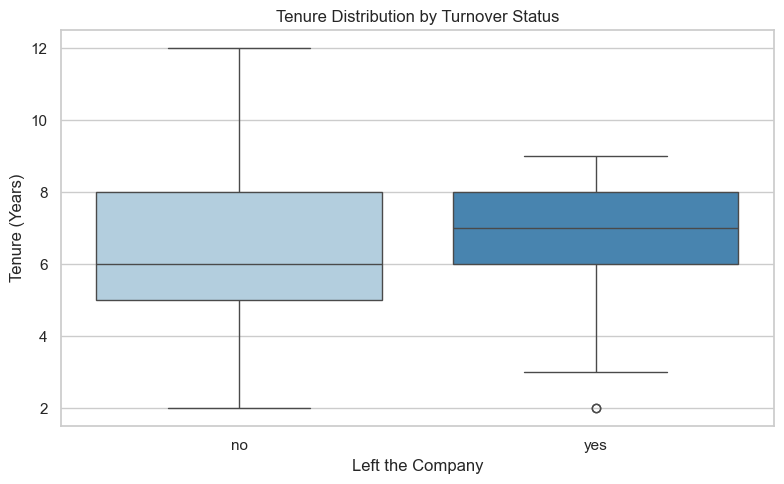

In [15]:
# Compare tenure distribution based on turnover status
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='left', y='tenure', hue='left', palette='Blues', legend=False)
plt.title('Tenure Distribution by Turnover Status')
plt.xlabel('Left the Company')
plt.ylabel('Tenure (Years)')
plt.tight_layout()
plt.show()


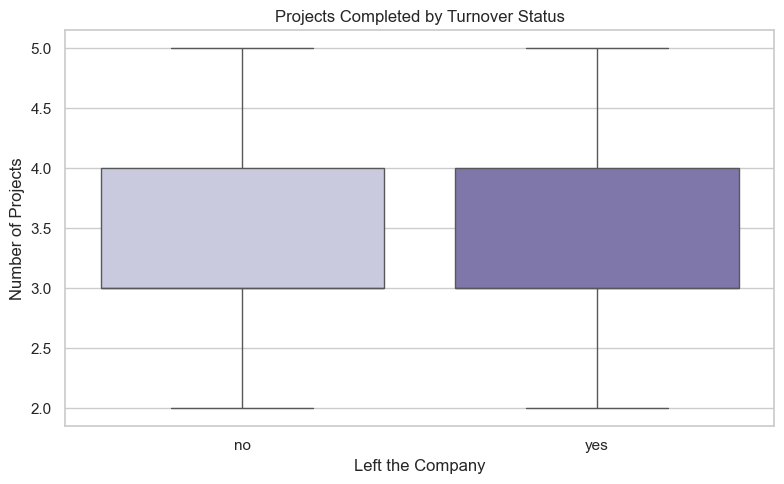

In [16]:
# Compare number of projects completed by employees who left vs stayed
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='left', y='projects', hue='left', palette='Purples', legend=False)
plt.title('Projects Completed by Turnover Status')
plt.xlabel('Left the Company')
plt.ylabel('Number of Projects')
plt.tight_layout()
plt.show()


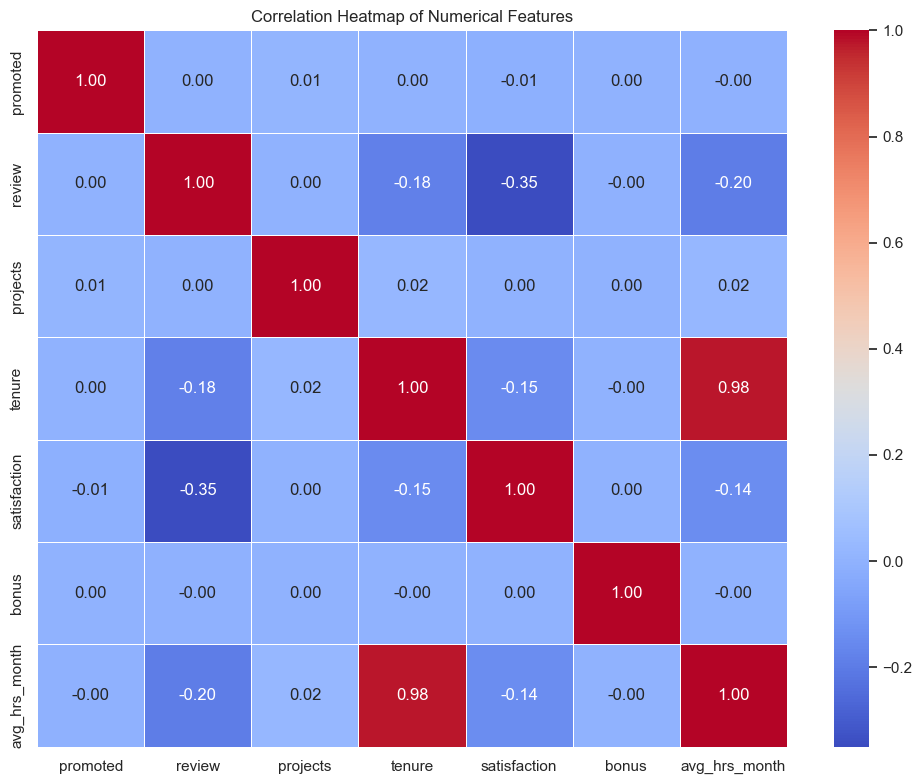

In [17]:
# Show correlation matrix between numerical features
plt.figure(figsize=(10, 8))
corr = df.select_dtypes(include=['float64', 'int64']).corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()
